# RQ1 Walkthrough — Chunking and Retrieval on One Sample Report

This notebook provides a **qualitative inspection** of the RQ1 pipeline by running it on a single company report and query. It complements the quantitative evaluation in `05_rq1_chunking_evaluation.ipynb`.

**What this notebook demonstrates:**

1. How each chunking strategy (fixed, structure-aware, semantic) and size (256, 512, 1024) segments the same report text — total chunks, token distributions, min/max.
2. What representative chunks look like: text content, page spans, and heading hierarchy metadata.
3. How the six retrieval methods rank chunks for one sample query — which passages each method surfaces and at which rank.
4. How chunk rankings shift between dense, sparse, and RRF fusion — visualising the complementarity of the two retrieval paradigms.

**Sample**: Shell 2024 sustainability report, first golden-standard question.

**Purpose in the thesis**: This walkthrough provides qualitative evidence that supports the quantitative RQ1 findings. It makes abstract metrics concrete by showing exactly what the pipeline produces at each stage.

## 1. Setup and Sample Selection

Load all 17 reports and the 204-sample golden standard, then select one company and its first query for the walkthrough. Shell is chosen because its 2024 report is representative of a large European energy company with comprehensive ESRS disclosures.

In [1]:
# ---------------------------------------------------------------------------
# Path setup and imports.
# We import the same modules used by the evaluation pipeline so this
# walkthrough exercises the exact same code paths.
# ---------------------------------------------------------------------------
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import matplotlib.pyplot as plt

from rag.config.settings import PipelineConfig
from rag.data.loaders import load_reports, load_golden_samples
from rag.chunking.strategies import build_chunks_for_config
from rag.indexing.embedder import EmbeddingService
from rag.indexing.qdrant_index import QdrantChunkIndex
from rag.retrieval.methods import Retriever

# Load the full corpus and golden standard.
reports = load_reports()
samples = load_golden_samples()

# Select one company and its first golden-standard query.
SAMPLE_COMPANY = "Shell"
SAMPLE_QUERY = next(s.question for s in samples if s.company == SAMPLE_COMPANY)

print(f"Company: {SAMPLE_COMPANY}")
print(f"Query:   {SAMPLE_QUERY[:120]}...")

Company: Shell
Query:   How has the undertaking conducted its double materiality assessment, and which sustainability matters were identified as...


## 2. Chunk Overview Across All Strategy/Size Combinations

We build chunks for all **9 strategy × size combinations** on the sample company's report and compare total chunk counts, mean/std token lengths, and min/max sizes. This shows how the three strategies differ in granularity and variance.

**Why this matters for RQ1:** The chunk overview table is the first piece of evidence that chunking strategy and size dramatically affect the number and shape of text segments fed to the retriever. For example, `fixed` chunking always produces near-uniform token counts (low std), while `structure_aware` and `semantic` produce high-variance distributions because they respect document structure or topic boundaries rather than a fixed window.

**Key things to look for:**
- `semantic` chunking tends to produce many more chunks than `fixed` or `structure_aware` because it splits on sentence-level coherence drops (even after the merging fix, some groups remain small).
- `structure_aware` chunk counts decrease with larger sizes because bigger windows can absorb entire subsections.
- The `std_tokens` column reveals how "uniform" each strategy's output is — a high standard deviation means the strategy adapts to content boundaries.

In [2]:
# ---------------------------------------------------------------------------
# Build chunks for all 9 strategy/size combinations on the sample report.
#
# For each of the 3 chunking strategies (fixed, structure_aware, semantic)
# and 3 chunk sizes (256, 512, 1024 tokens), we call build_chunks_for_config()
# which returns both the list of ChunkRecord objects and a ChunkStats summary.
#
# We store the chunks in a dict keyed by (strategy, size) for later reuse
# in the retrieval comparison (Section 4), and collect summary statistics
# into a DataFrame for display.
#
# The retrieval_method in PipelineConfig is set to "hybrid_rrf" here but
# it does not affect chunking — it is only used later during retrieval.
# ---------------------------------------------------------------------------
records = []
all_chunks_by_cfg = {}
for strategy in ["fixed", "structure_aware", "semantic"]:
    for size in [256, 512, 1024]:
        cfg = PipelineConfig(chunk_strategy=strategy, chunk_size=size, retrieval_method="hybrid_rrf")
        chunks, stats = build_chunks_for_config({SAMPLE_COMPANY: reports[SAMPLE_COMPANY]}, cfg)
        all_chunks_by_cfg[(strategy, size)] = chunks
        records.append({
            "strategy": strategy, "size": size,
            "total_chunks": stats.total_chunks,
            "mean_tokens": round(stats.mean_tokens, 1),
            "std_tokens": round(stats.std_tokens, 1),
            "min_tokens": stats.min_tokens,
            "max_tokens": stats.max_tokens,
        })

# Display the overview table sorted by strategy then size for readability.
chunk_overview = pd.DataFrame(records).sort_values(["strategy", "size"])
chunk_overview

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,strategy,size,total_chunks,mean_tokens,std_tokens,min_tokens,max_tokens
0,fixed,256,853,255.8,2.1,200,258
1,fixed,512,427,511.1,15.1,200,514
2,fixed,1024,214,1020.0,56.2,200,1026
6,semantic,256,1141,177.5,80.1,2,257
7,semantic,512,735,272.3,177.2,2,513
8,semantic,1024,578,343.0,330.2,2,1025
3,structure_aware,256,1067,197.3,79.0,2,258
4,structure_aware,512,701,295.1,187.6,2,514
5,structure_aware,1024,557,367.0,359.6,2,1025


## 3. Inspect Representative Chunks

Preview the first few chunks for a chosen strategy/size to see how text is segmented, what page spans look like, and whether the heading hierarchy is preserved.

**Why `structure_aware` / 512 is shown here:** This combination is representative of a "middle ground" configuration — it respects the document's Markdown heading hierarchy (H1–H3) while keeping chunks at a moderate size. The `header_hierarchy` column demonstrates that structure-aware chunking preserves section context (e.g., "Sustainability Statements > General disclosures > GHG emissions"), which provides useful metadata for downstream retrieval and generation.

**What to look for:**
- The `headers` column shows the heading breadcrumb trail — this is only populated for `structure_aware` chunking.
- Token counts vary because sections have different lengths; chunks are split only when they exceed the token ceiling.
- `page_start`–`page_end` spans show how chunks map back to the original PDF pages.

In [3]:
# ---------------------------------------------------------------------------
# Preview helper: display the first n chunks for a given strategy/size.
#
# For each chunk, we show:
#   - chunk_id (truncated to 12 chars for display)
#   - token_count: number of tiktoken cl100k_base tokens
#   - pages: page_start–page_end from the original PDF
#   - headers: the heading hierarchy breadcrumb (structure_aware only)
#   - text_preview: first 300 characters of raw text
#
# This function reuses the all_chunks_by_cfg dict built in Section 2.
# ---------------------------------------------------------------------------
def preview_chunks(strategy: str, size: int, n: int = 3):
    chunks = all_chunks_by_cfg[(strategy, size)]
    rows = []
    for c in chunks[:n]:
        rows.append({
            "chunk_id": c.chunk_id[:12],
            "tokens": c.token_count,
            "pages": f"{c.page_start}-{c.page_end}",
            "headers": " > ".join(c.header_hierarchy) if c.header_hierarchy else "",
            "text_preview": c.text[:300],
        })
    return pd.DataFrame(rows)

# Show 5 representative chunks from structure_aware/512.
preview_chunks("structure_aware", 512, n=5)

,chunk_id,tokens,pages,headers,text_preview
0,237da278e79b,214,None-341,Sustainability Statements,# Sustainability Statements\n\n\n\n\n| 342 | G...
1,70c51bf0b0a5,9,342-342,Sustainability Statements > General disclosure...,## General disclosures (ESRS 2)
2,48d61d1ef698,470,342-342,Sustainability Statements > General disclosure...,### General basis for preparation of Sustainab...
3,1bdb6568ab25,369,342-342,Sustainability Statements > General disclosure...,### Understanding differences in reporting bou...
4,ae7e02a3b2bf,376,342-342,Sustainability Statements > General disclosure...,### Greenhouse gas (GHG) emissions\n\nThe GHG ...


## 4. Retrieval Comparison Across All Six Methods

Using one base chunking configuration (`structure_aware` / 512 tokens), we index the chunks in Qdrant and run the same query through all six retrieval methods: dense, dense + rerank, sparse (BM25), sparse + rerank, hybrid RRF, and hybrid + rerank. This **isolates the effect of the retrieval method** while holding chunking constant.

**Why `structure_aware` / 512?** This is a representative mid-range configuration. The choice does not affect the comparative conclusions about retrieval methods — it simply provides a concrete set of chunks to retrieve from.

**The six retrieval methods:**
1. **Dense**: Cosine similarity between query and chunk embeddings (`text-embedding-3-large`, 3072 dims) in Qdrant.
2. **Dense + Rerank**: Dense retrieval with 3× candidate pool, then cross-encoder re-scoring (`cross-encoder/ms-marco-MiniLM-L-6-v2`).
3. **Sparse (BM25)**: Okapi BM25 term-frequency matching (Robertson et al., 1994).
4. **Sparse + Rerank**: BM25 with cross-encoder re-scoring.
5. **Hybrid RRF**: Reciprocal Rank Fusion (k=60) combining dense and sparse rankings (Cormack et al., 2009).
6. **Hybrid + Rerank**: RRF with cross-encoder re-scoring.

In [4]:
# ---------------------------------------------------------------------------
# Retrieval comparison: index chunks and run the same query through all 6 methods.
#
# Step 1: Select the base chunking configuration (structure_aware / 512).
# Step 2: Create an EmbeddingService to compute text-embedding-3-large vectors.
# Step 3: Build a Qdrant collection for this configuration and upsert all
#          chunk vectors. This is the same indexing step used in the full
#          RQ1 evaluation pipeline (rq1_runner.py).
# Step 4: Instantiate a Retriever with the base config.
# Step 5: Loop over all 6 retrieval methods, updating the config each time,
#          and retrieve top-15 chunks for the sample query. The Retriever
#          internally dispatches to the correct method (dense/sparse/hybrid)
#          and optionally applies cross-encoder reranking.
#
# Note: Reranked variants (dense_rerank, sparse_rerank, hybrid_rerank)
# first retrieve 3× top_k candidates from the base method, then re-score
# using the cross-encoder to improve precision at the top ranks.
# ---------------------------------------------------------------------------
BASE_STRATEGY = "structure_aware"
BASE_SIZE = 512
chunks = all_chunks_by_cfg[(BASE_STRATEGY, BASE_SIZE)]

# Embed all chunk texts and index them in Qdrant.
embedder = EmbeddingService(load_cache=False)
qdrant = QdrantChunkIndex(dims=embedder.dims)
collection_name = qdrant.collection_name(BASE_STRATEGY, BASE_SIZE)
qdrant.recreate_collection(collection_name)
vectors = embedder.embed_texts([c.text for c in chunks])
qdrant.upsert_chunks(collection_name, chunks, vectors)

# Create a Retriever instance (config will be swapped per method).
cfg = PipelineConfig(
    chunk_strategy=BASE_STRATEGY, chunk_size=BASE_SIZE,
    retrieval_method="dense", top_k=15,
)
r = Retriever(chunks=chunks, config=cfg, embedder=embedder, qdrant=qdrant)

# Run retrieval for each of the 6 methods and store the results.
method_to_hits = {}
for method in ["dense", "dense_rerank", "sparse", "sparse_rerank", "hybrid_rrf", "hybrid_rerank"]:
    r.config = PipelineConfig(
        chunk_strategy=BASE_STRATEGY, chunk_size=BASE_SIZE,
        retrieval_method=method, top_k=15,
    )
    try:
        method_to_hits[method] = r.retrieve(SAMPLE_QUERY, company=SAMPLE_COMPANY, top_k=15)
    except Exception as exc:
        print(f"Skipping {method}: {exc}")

print(f"Completed retrieval for: {list(method_to_hits.keys())}")

/Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulation-Bot/rag/indexing/qdrant_index.py:19: UserWarning: Local mode is not recommended for collections with more than 20,000 points. Collection <rq1_esrs_semantic_256> contains 32426 points. Consider using Qdrant in Docker or Qdrant Cloud for better performance with large datasets.
  self.client = QdrantClient(path=str(QDRANT_STORAGE_PATH))
/Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulation-Bot/rag/indexing/qdrant_index.py:19: UserWarning: Local mode is not recommended for collections with more than 20,000 points. Collection <rq1_esrs_semantic_512> contains 30149 points. Consider using Qdrant in Docker or Qdrant Cloud for better performance with large datasets.
  self.client = QdrantClient(path=str(QDRANT_STORAGE_PATH))
/Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulatio

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: cross-encoder/ms-marco-MiniLM-L-6-v2
Key                          | Status     |  | 
-----------------------------+------------+--+-
bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Completed retrieval for: ['dense', 'dense_rerank', 'sparse', 'sparse_rerank', 'hybrid_rrf', 'hybrid_rerank']


## 5. Retrieved Chunks per Method

The tables below show the top-10 retrieved chunks for each method, including rank, score, page span, and a text preview. Compare which passages each method surfaces and at which rank.

**How to read the tables:**
- **rank**: Position in the result list (1 = top result). Lower is better.
- **score**: The retrieval score. Scale differs by method: dense uses cosine similarity (0–1), BM25 uses term-frequency scores (unbounded), RRF uses reciprocal-rank scores (~0.01–0.03), and reranked variants use cross-encoder logits.
- **chunk_id**: First 12 characters of the SHA-256 hash that uniquely identifies each chunk.
- **pages**: The PDF page range this chunk originates from.

**Key observations to look for:**
- Do all methods agree on the top-1 chunk, or do they surface different passages?
- Reranked variants share the same chunk_id pool as their base method (same candidates, different ordering).
- BM25 tends to favour chunks with exact ESRS terminology; dense retrieval captures semantic paraphrases.

In [5]:
# ---------------------------------------------------------------------------
# Display the top-10 retrieved chunks for each retrieval method.
#
# hits_to_df() converts a list of RetrievalHit objects into a DataFrame
# for display. Each hit contains:
#   - rank: position in the ranked result list
#   - score: retrieval score (scale varies by method — see markdown above)
#   - chunk: the full ChunkRecord with text, page spans, metadata
#
# We handle NaN scores gracefully (can occur if a method fails to score
# a candidate) by displaying "NaN" as a string.
#
# The loop iterates over all 6 methods in a logical order: base methods
# first (dense, sparse, hybrid_rrf), then their reranked variants.
# ---------------------------------------------------------------------------
import math

def hits_to_df(method: str):
    """Convert retrieval hits for a method into a display DataFrame."""
    rows = []
    for h in method_to_hits.get(method, []):
        score_val = h.score
        score_display = round(score_val, 4) if not math.isnan(score_val) else "NaN"
        rows.append({
            "method": method, "rank": h.rank,
            "score": score_display,
            "chunk_id": h.chunk.chunk_id[:12],
            "pages": f"{h.chunk.page_start}-{h.chunk.page_end}",
            "text_preview": h.chunk.text[:220],
        })
    return pd.DataFrame(rows)

# Display top-10 for each method.
for m in ["dense", "dense_rerank", "sparse", "sparse_rerank", "hybrid_rrf", "hybrid_rerank"]:
    print(f"\n--- {m} ---")
    display(hits_to_df(m).head(10))


--- dense ---


,method,rank,score,chunk_id,pages,text_preview
0,dense,1,0.6526,0821d73159cf,357-357,### Other methodological notes\n\nWe engage wi...
1,dense,2,0.6523,663349512d35,350-351,well as whether such matters trigger or could ...
2,dense,3,0.6290,72d54d64abc5,354-354,## Description of the process to identify and ...
3,dense,4,0.6163,8a5c4d1801bd,438-438,### Emphasis of matter - The double materialit...
4,dense,5,0.6015,5095339d359f,354-355,we assess potential magnitude on a gross basis...
5,dense,6,0.5985,f22d11ba37c1,350-350,"informed by the views, interests and rights of..."
6,dense,7,0.5936,8b6ba3dc2317,351-351,materiality assessment process uses qualitativ...
7,dense,8,0.5748,938d26557324,397-397,## Our activities can affect natural habitats ...
8,dense,9,0.5658,84b6b565e7ea,358-358,uneration policies linked to sustainability (p...
9,dense,10,0.5559,2cee16beefd6,355-355,or depict and the relevance of the data point ...



--- dense_rerank ---


,method,rank,score,chunk_id,pages,text_preview
0,dense_rerank,1,5.4929,663349512d35,350-351,well as whether such matters trigger or could ...
1,dense_rerank,2,5.4273,8a5c4d1801bd,438-438,### Emphasis of matter - The double materialit...
2,dense_rerank,3,4.7674,72d54d64abc5,354-354,## Description of the process to identify and ...
3,dense_rerank,4,4.0634,2f91367c673e,424-424,"## Our core values of honesty, integrity and r..."
4,dense_rerank,5,3.6006,8b6ba3dc2317,351-351,materiality assessment process uses qualitativ...
5,dense_rerank,6,3.1551,97dfdacbad5d,404-404,"## As part of our respecting nature ambition, ..."
6,dense_rerank,7,3.0953,972aa7e6e982,408-408,## Our people are essential to our purpose of ...
7,dense_rerank,8,2.9129,6c90ba86de94,437-438,### Conclusion\n\nBased on the procedures perf...
8,dense_rerank,9,2.5385,938d26557324,397-397,## Our activities can affect natural habitats ...
9,dense_rerank,10,2.4728,f22d11ba37c1,350-350,"informed by the views, interests and rights of..."



--- sparse ---


...

,method,rank,score,chunk_id,pages,text_preview
0,sparse_rerank,1,5.4929,663349512d35,350-351,well as whether such matters trigger or could ...
1,sparse_rerank,2,5.4273,8a5c4d1801bd,438-438,### Emphasis of matter - The double materialit...
2,sparse_rerank,3,4.7674,72d54d64abc5,354-354,## Description of the process to identify and ...
3,sparse_rerank,4,4.0634,2f91367c673e,424-424,"## Our core values of honesty, integrity and r..."
4,sparse_rerank,5,3.6006,8b6ba3dc2317,351-351,materiality assessment process uses qualitativ...
5,sparse_rerank,6,3.1551,97dfdacbad5d,404-404,"## As part of our respecting nature ambition, ..."
6,sparse_rerank,7,3.0953,972aa7e6e982,408-408,## Our people are essential to our purpose of ...
7,sparse_rerank,8,2.9129,6c90ba86de94,437-438,### Conclusion\n\nBased on the procedures perf...
8,sparse_rerank,9,2.5385,938d26557324,397-397,## Our activities can affect natural habitats ...
9,sparse_rerank,10,2.4728,f22d11ba37c1,350-350,"informed by the views, interests and rights of..."



--- hybrid_rrf ---


,method,rank,score,chunk_id,pages,text_preview
0,hybrid_rrf,1,0.0323,663349512d35,350-351,well as whether such matters trigger or could ...
1,hybrid_rrf,2,0.0315,f22d11ba37c1,350-350,"informed by the views, interests and rights of..."
2,hybrid_rrf,3,0.0315,8a5c4d1801bd,438-438,### Emphasis of matter - The double materialit...
3,hybrid_rrf,4,0.0308,5095339d359f,354-355,we assess potential magnitude on a gross basis...
4,hybrid_rrf,5,0.0307,0821d73159cf,357-357,### Other methodological notes\n\nWe engage wi...
5,hybrid_rrf,6,0.0306,72d54d64abc5,354-354,## Description of the process to identify and ...
6,hybrid_rrf,7,0.0306,8b6ba3dc2317,351-351,materiality assessment process uses qualitativ...
7,hybrid_rrf,8,0.0284,938d26557324,397-397,## Our activities can affect natural habitats ...
8,hybrid_rrf,9,0.0283,deebad9981e6,353-353,## Current and anticipated effects on business...
9,hybrid_rrf,10,0.0270,a35e20de04d3,439-439,## Our approach\n\nThe objective of a limited ...



--- hybrid_rerank ---


,method,rank,score,chunk_id,pages,text_preview
0,hybrid_rerank,1,5.4929,663349512d35,350-351,well as whether such matters trigger or could ...
1,hybrid_rerank,2,5.4273,8a5c4d1801bd,438-438,### Emphasis of matter - The double materialit...
2,hybrid_rerank,3,4.7674,72d54d64abc5,354-354,## Description of the process to identify and ...
3,hybrid_rerank,4,4.0634,2f91367c673e,424-424,"## Our core values of honesty, integrity and r..."
4,hybrid_rerank,5,3.6006,8b6ba3dc2317,351-351,materiality assessment process uses qualitativ...
5,hybrid_rerank,6,3.1551,97dfdacbad5d,404-404,"## As part of our respecting nature ambition, ..."
6,hybrid_rerank,7,3.0953,972aa7e6e982,408-408,## Our people are essential to our purpose of ...
7,hybrid_rerank,8,2.9129,6c90ba86de94,437-438,### Conclusion\n\nBased on the procedures perf...
8,hybrid_rerank,9,2.5385,938d26557324,397-397,## Our activities can affect natural habitats ...
9,hybrid_rerank,10,2.4728,f22d11ba37c1,350-350,"informed by the views, interests and rights of..."


## 6. Ranking Shifts Across Base Methods

For chunks that appear in the top results of **all three** base retrieval methods (dense, sparse, hybrid RRF), we compare how their rank changes. This visualizes whether RRF fusion successfully combines the strengths of dense and sparse retrieval.

**Why only the three base methods?** Reranked variants use the same candidate pools as their base methods — they just re-order the candidates using a cross-encoder. Including them would clutter the plot without adding new information about retrieval complementarity.

**How to read the plot:**
- Each point on the x-axis is a chunk (identified by truncated chunk_id).
- The y-axis shows rank (inverted: rank 1 at top, higher ranks below).
- Lines connect the same chunk across the three methods.
- **Converging lines** indicate methods agree on a chunk's importance.
- **Diverging lines** show chunks where dense and sparse disagree — these are the cases where RRF fusion adds the most value by combining both signals.

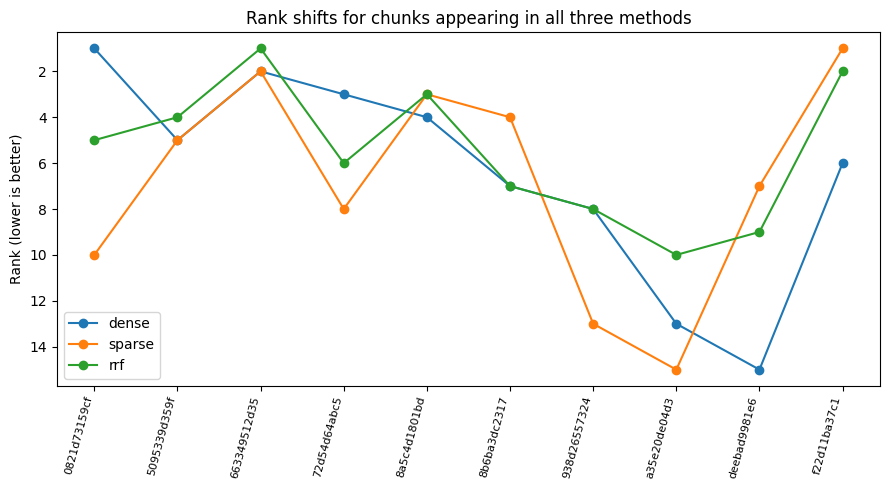

In [6]:
# ---------------------------------------------------------------------------
# Ranking shift visualisation: compare how the same chunks are ranked by
# dense, sparse, and hybrid RRF retrieval.
#
# Step 1: Convert each method's hit list into a {chunk_id: rank} dict.
# Step 2: Find chunk_ids that appear in ALL three methods' top results.
#          Only these "common" chunks can be meaningfully compared.
# Step 3: Build a DataFrame with one row per common chunk and columns for
#          each method's rank.
# Step 4: Plot rank vs. chunk for each method. The y-axis is inverted so
#          rank 1 appears at the top (best position).
#
# If no chunks are shared across all three methods (unlikely but possible
# for very different queries), a fallback message is printed.
# ---------------------------------------------------------------------------
dense_df = hits_to_df("dense")
sparse_df = hits_to_df("sparse")
rrf_df = hits_to_df("hybrid_rrf")

def build_rank_map(df):
    """Map chunk_id -> rank from a hits DataFrame."""
    if df.empty:
        return {}
    return dict(zip(df["chunk_id"], df["rank"]))

rank_dense = build_rank_map(dense_df)
rank_sparse = build_rank_map(sparse_df)
rank_rrf = build_rank_map(rrf_df)

# Find chunks appearing in all three methods' results.
common_ids = sorted(set(rank_dense) & set(rank_sparse) & set(rank_rrf))[:20]
plot_rows = [{"chunk_id": cid, "dense": rank_dense[cid],
              "sparse": rank_sparse[cid], "rrf": rank_rrf[cid]}
             for cid in common_ids]
rank_cmp = pd.DataFrame(plot_rows)

if not rank_cmp.empty:
    fig, ax = plt.subplots(figsize=(9, 5))
    x = range(len(rank_cmp))
    for col in ["dense", "sparse", "rrf"]:
        ax.plot(x, rank_cmp[col], marker="o", label=col)
    ax.set_xticks(list(x))
    ax.set_xticklabels(rank_cmp["chunk_id"], rotation=75, ha="right", fontsize=8)
    ax.set_ylabel("Rank (lower is better)")
    ax.set_title("Rank shifts for chunks appearing in all three methods")
    ax.legend()
    ax.invert_yaxis()  # Rank 1 at top.
    plt.tight_layout()
    plt.show()
else:
    print("No shared chunks across all three methods for this query.")

## Interpretation

**What to look for in the output above:**

- **Chunk overview (Section 2)**: `fixed` chunking produces uniform-size chunks (very low std); `structure_aware` respects heading boundaries (resulting in variable sizes that match the document's logical structure); `semantic` splits on sentence-level coherence drops (often producing many small chunks, even after the greedy merging fix applied in `strategies.py`).

- **Dense vs. Sparse (Section 5)**: Dense retrieval (cosine similarity on `text-embedding-3-large` embeddings) captures **semantic similarity** — it can match paraphrases and conceptually related passages even without shared keywords. Sparse retrieval (BM25) captures **exact ESRS terminology** — it excels when the query and the relevant passage share specific technical terms like "double materiality assessment" or "GHG emissions". They often surface different chunks in different orders, demonstrating their complementary strengths.

- **RRF fusion (Section 6)**: Reciprocal Rank Fusion (k=60) combines dense and sparse rankings. Chunks ranked highly by **both** methods are promoted to the top of the fused list; chunks found by only one method still appear but at lower combined ranks. The ranking shift plot makes this visible: when the dense and sparse lines diverge for a chunk, the RRF line typically falls between them (compromise ranking).

- **Reranking (Sections 4–5)**: Each base retrieval method has a reranked variant (`dense_rerank`, `sparse_rerank`, `hybrid_rerank`). The reranked variant retrieves a wider candidate pool (3× `top_k`) from the base method, then a cross-encoder (`cross-encoder/ms-marco-MiniLM-L-6-v2`) re-scores those candidates. The cross-encoder considers full query-passage interaction (not just embedding similarity), which improves **precision at the top ranks**. Notice that reranked variants often share the same top-1 chunk across all three base methods — the cross-encoder converges on the most relevant passage regardless of the initial retrieval signal.

**Connection to RQ1**: This walkthrough provides **qualitative evidence** that supports the quantitative findings in `05_rq1_chunking_evaluation.ipynb`. The abstract metrics (Recall@k, nDCG@10, MRR@10) become concrete when you can see exactly which passages each method retrieves and how the rankings differ.

---
*End of walkthrough. See `05_rq1_chunking_evaluation.ipynb` for the full quantitative RQ1 evaluation across all 54 configurations with statistical significance testing.*